In [1]:
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler

In [2]:
df = pd.read_csv('TSLA.csv')
df.head()

,Date,Open,High,Low,Close,Adj Close,Volume
0,8/16/2016,45.098000,45.438000,44.681999,44.722000,44.722000,11335500
1,8/17/2016,44.866001,44.966000,44.560001,44.647999,44.647999,8935500
2,8/18/2016,44.764000,45.132000,44.458000,44.702000,44.702000,8572500
3,8/19/2016,44.708000,45.034000,44.506001,45.000000,45.000000,8297500
4,8/22/2016,44.834000,45.021999,44.535999,44.585999,44.585999,10327500


In [3]:
raw_prices = df['Close'].values.reshape(-1, 1)

#  Compute first-order differences to make the data stationary
price_diffs = np.diff(raw_prices, axis=0)

In [4]:
import plotly.express as px

fig= px.line(df, x='Date', y='Close', title='Tesla Close Price')
fig.show()

In [5]:
diff_scaler = MinMaxScaler(feature_range=(-1, 1))
scaled_diffs = diff_scaler.fit_transform(price_diffs)

In [6]:
train_size_diff = int(len(scaled_diffs) * 0.70)
train_diff_data = scaled_diffs[:train_size_diff]
test_diff_data = scaled_diffs[train_size_diff:]

In [7]:
def create_diff_dataset(dataset, time_step=15):
    X, y = [], []
    for i in range(len(dataset) - time_step):
        X.append(dataset[i : i + time_step, 0])
        y.append(dataset[i + time_step, 0])
    return np.array(X), np.array(y)

time_step = 15
X_train_diff, y_train_diff = create_diff_dataset(train_diff_data, time_step)
X_test_diff, y_test_diff = create_diff_dataset(test_diff_data, time_step)

In [8]:
rf_diff_model = RandomForestRegressor(n_estimators=500, random_state=42)
rf_diff_model.fit(X_train_diff, y_train_diff)

RandomForestRegressor(n_estimators=500, random_state=42)

In [9]:
pred_diffs_scaled = rf_diff_model.predict(X_test_diff)
pred_diffs = diff_scaler.inverse_transform(pred_diffs_scaled.reshape(-1, 1))

In [10]:
start_idx = train_size_diff + time_step
actual_prices_test = raw_prices[start_idx + 1:]

# Reconstructing prices step-by-step using actual preceding values to avoid compounding errors (1-step ahead forecasting)
reconstructed_preds = []
for i in range(len(pred_diffs)):
    prev_actual_price = raw_prices[start_idx + i]
    predicted_price = prev_actual_price + pred_diffs[i]
    reconstructed_preds.append(predicted_price)

reconstructed_preds = np.array(reconstructed_preds).flatten()
actual_prices_test = actual_prices_test.flatten()[:len(reconstructed_preds)]

In [11]:
from sklearn.metrics import mean_squared_error, mean_absolute_error
import math

mae = mean_absolute_error(actual_prices_test, reconstructed_preds)
rmse = math.sqrt(mean_squared_error(actual_prices_test, reconstructed_preds))

print(f"New Mean Absolute Error (MAE): {mae:.2f}")
print(f"New Root Mean Squared Error (RMSE): {rmse:.2f}")

New Mean Absolute Error (MAE): 15.19
New Root Mean Squared Error (RMSE): 21.24


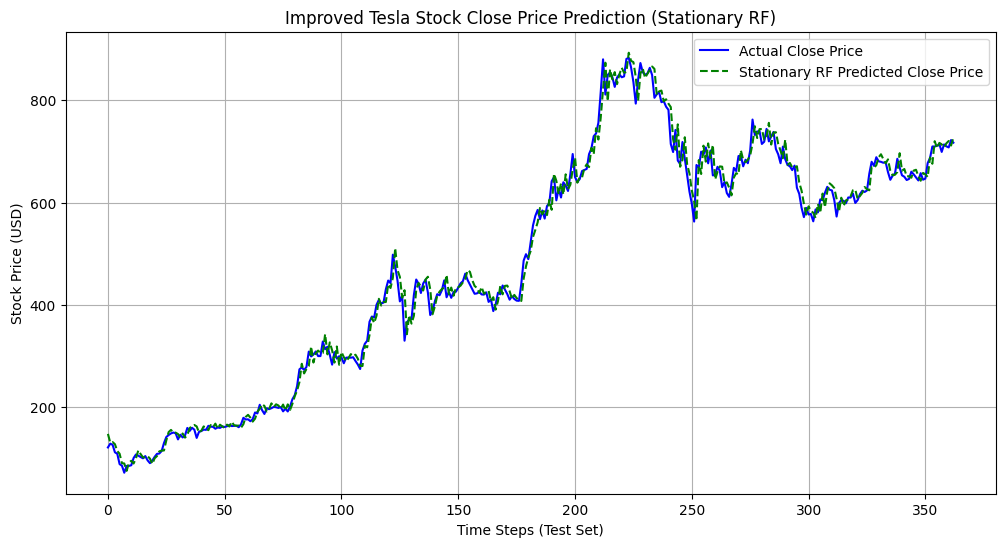

In [12]:
# Plot the improved prediction results
plt.figure(figsize=(12, 6))
plt.plot(actual_prices_test, label='Actual Close Price', color='blue')
plt.plot(reconstructed_preds, label='Stationary RF Predicted Close Price', color='green', linestyle='--')
plt.title('Improved Tesla Stock Close Price Prediction (Stationary RF)')
plt.xlabel('Time Steps (Test Set)')
plt.ylabel('Stock Price (USD)')
plt.legend()
plt.grid(True)
plt.show()